# Differentiable simulation example 1: Twiss matching with four thin-lens quadrupoles

Copyright (C) 2026 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

## Overview

A beamline consists of five drift spaces with four thin-lens quadrupoles in between:

```
entrance -- D1 -- Q1 -- D2 -- Q2 -- D3 -- Q3 -- D4 -- Q4 -- D5 -- exit
```

- The entrance Twiss parameters $(\beta_x, \alpha_x, \beta_y, \alpha_y)$ are drawn at random, but are treated as known.
- The exit Twiss parameters are fixed to target values.
- The four integrated quadrupole strengths $k_i = K_{1,i} L_i$ [1/m] are the knobs.

Four knobs and four constraints make a square problem. The whole beamline is written in JAX,
so the gradient (and the Jacobian) of the mismatch with respect to the knobs is obtained by automatic
differentiation rather than by finite differences.

## Physics

Transfer matrices (one transverse plane):

$$
M_\text{drift}(L) = \begin{pmatrix} 1 & L \\ 0 & 1 \end{pmatrix}, \qquad
M_\text{quad}(k) = \begin{pmatrix} 1 & 0 \\ \mp k & 1 \end{pmatrix}
$$

where the upper (lower) sign is for the horizontal (vertical) plane, and $k > 0$ focuses horizontally.

The beam envelope is represented by the Twiss matrix

$$
T = \begin{pmatrix} \beta & -\alpha \\ -\alpha & \gamma \end{pmatrix}, \qquad \gamma = \frac{1 + \alpha^2}{\beta},
$$

which is transported as $T_1 = M T_0 M^\mathsf{T}$.

The mismatch between the obtained Twiss $(\beta, \alpha, \gamma)$ and the target $(\beta_t, \alpha_t, \gamma_t)$
is measured by the mismatch parameter (BMAG)

$$
B = \tfrac{1}{2} \left( \beta_t \gamma - 2 \alpha_t \alpha + \gamma_t \beta \right) \ge 1,
$$

which equals 1 if and only if the two ellipses coincide. The loss function is $\mathcal{L} = (B_x - 1) + (B_y - 1)$.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# Use double precision; the default float32 is too coarse to reach a tight match.
jax.config.update("jax_enable_x64", True)
%matplotlib inline

## Beamline and problem setup

In [2]:
DRIFT_LENGTHS = jnp.array([2.0, 1.5, 1.5, 1.5, 2.0])  # [m], D1 ... D5
N_QUADS = 4

# Random (but known) entrance Twiss parameters
ENTRANCE_SEED = 0
BETA_MIN, BETA_MAX = 2.0, 15.0  # [m]
ALPHA_MIN, ALPHA_MAX = -1.5, 1.5

key = jax.random.PRNGKey(ENTRANCE_SEED)
key_beta, key_alpha = jax.random.split(key)
beta0 = jax.random.uniform(key_beta, (2,), minval=BETA_MIN, maxval=BETA_MAX)
alpha0 = jax.random.uniform(key_alpha, (2,), minval=ALPHA_MIN, maxval=ALPHA_MAX)
TWISS_IN = jnp.stack([beta0, alpha0], axis=1)  # shape (2 planes, [beta, alpha])

# Fixed exit (target) Twiss parameters
TWISS_TARGET = jnp.array(
    [
        [5.0, 0.0],  # x: beta [m], alpha
        [3.0, 0.0],  # y: beta [m], alpha
    ]
)

PLANES = ("x", "y")
for i, p in enumerate(PLANES):
    print(f"entrance {p}: beta = {TWISS_IN[i, 0]:7.4f} m, alpha = {TWISS_IN[i, 1]:+7.4f}")
for i, p in enumerate(PLANES):
    print(f"target   {p}: beta = {TWISS_TARGET[i, 0]:7.4f} m, alpha = {TWISS_TARGET[i, 1]:+7.4f}")

entrance x: beta = 14.6093 m, alpha = -1.2581
entrance y: beta =  6.0974 m, alpha = +1.2718
target   x: beta =  5.0000 m, alpha = +0.0000
target   y: beta =  3.0000 m, alpha = +0.0000


## Forward model (pure JAX functions)

Every function below is a pure function of JAX arrays, so `jax.grad`, `jax.jacfwd`, `jax.jit`, and `jax.vmap`
can be applied freely.

In [3]:
def drift_matrix(length):
    return jnp.array([[1.0, length], [0.0, 1.0]])


def thin_quad_matrix(k, sign):
    """sign = +1 for x (focusing when k > 0), -1 for y."""
    return jnp.array([[1.0, 0.0], [-sign * k, 1.0]])


PLANE_SIGNS = jnp.array([1.0, -1.0])  # x, y


def twiss_to_matrix(beta, alpha):
    gamma = (1.0 + alpha**2) / beta
    return jnp.array([[beta, -alpha], [-alpha, gamma]])


def matrix_to_twiss(t):
    return jnp.array([t[0, 0], -t[0, 1]])


def transfer_matrix(k, sign):
    """One-plane transfer matrix of D1 Q1 D2 Q2 D3 Q3 D4 Q4 D5."""
    m = drift_matrix(DRIFT_LENGTHS[0])
    for i in range(N_QUADS):
        m = thin_quad_matrix(k[i], sign) @ m
        m = drift_matrix(DRIFT_LENGTHS[i + 1]) @ m
    return m


def propagate_twiss(k, twiss_in=TWISS_IN):
    """Exit Twiss parameters, shape (2 planes, [beta, alpha])."""

    def one_plane(twiss, sign):
        m = transfer_matrix(k, sign)
        t1 = m @ twiss_to_matrix(twiss[0], twiss[1]) @ m.T
        return matrix_to_twiss(t1)

    return jax.vmap(one_plane)(twiss_in, PLANE_SIGNS)


def bmag(twiss, twiss_target):
    beta, alpha = twiss
    beta_t, alpha_t = twiss_target
    gamma = (1.0 + alpha**2) / beta
    gamma_t = (1.0 + alpha_t**2) / beta_t
    return 0.5 * (beta_t * gamma - 2.0 * alpha_t * alpha + gamma_t * beta)


@jax.jit
def loss_fn(k):
    twiss_out = propagate_twiss(k)
    return jnp.sum(jax.vmap(bmag)(twiss_out, TWISS_TARGET) - 1.0)


loss_and_grad = jax.jit(jax.value_and_grad(loss_fn))

### Check the automatic derivative against central finite differences

In [4]:
FD_STEP = 1.0e-6
k_test = jnp.array([0.3, -0.4, 0.5, -0.2])

_, grad_ad = loss_and_grad(k_test)
eye = jnp.eye(N_QUADS)
grad_fd = jnp.array([(loss_fn(k_test + FD_STEP * eye[i]) - loss_fn(k_test - FD_STEP * eye[i])) / (2.0 * FD_STEP)
                     for i in range(N_QUADS)])
print("autodiff gradient   :", np.asarray(grad_ad))
print("finite-diff gradient:", np.asarray(grad_fd))
print("max abs difference  :", float(jnp.max(jnp.abs(grad_ad - grad_fd))))

autodiff gradient   : [15.41649011 22.56041255 34.45972008 15.45534164]
finite-diff gradient: [15.41649011 22.56041255 34.45972008 15.45534164]
max abs difference  : 1.6133956393105109e-09


## Step 1: gradient-based optimization with Adam (multi-start)

The loss landscape has several local minima, so we run Adam from many random initial guesses at once.
The optimizer loop is written with `jax.lax.scan` and vectorized over the initial guesses with `jax.vmap`;
the whole multi-start optimization is compiled into one XLA program by `jax.jit`.

In [5]:
N_STARTS = 64
K_INIT_MAX = 1.0  # [1/m], initial guesses are uniform in [-K_INIT_MAX, K_INIT_MAX]
N_ADAM_STEPS = 3000
LEARNING_RATE = 1.0e-2
ADAM_BETA1, ADAM_BETA2, ADAM_EPS = 0.9, 0.999, 1.0e-12
INIT_SEED = 1


def adam(k0):
    """Plain Adam written with lax.scan. Returns the final k and the loss history."""

    def step(state, i):
        k, m, v = state
        loss, g = loss_and_grad(k)
        m = ADAM_BETA1 * m + (1.0 - ADAM_BETA1) * g
        v = ADAM_BETA2 * v + (1.0 - ADAM_BETA2) * g**2
        m_hat = m / (1.0 - ADAM_BETA1 ** (i + 1))
        v_hat = v / (1.0 - ADAM_BETA2 ** (i + 1))
        k = k - LEARNING_RATE * m_hat / (jnp.sqrt(v_hat) + ADAM_EPS)
        return (k, m, v), loss

    state0 = (k0, jnp.zeros_like(k0), jnp.zeros_like(k0))
    (k_final, _, _), history = jax.lax.scan(step, state0, jnp.arange(N_ADAM_STEPS))
    return k_final, history


k_inits = jax.random.uniform(jax.random.PRNGKey(INIT_SEED), (N_STARTS, N_QUADS), minval=-K_INIT_MAX, maxval=K_INIT_MAX)
k_adam, loss_history = jax.jit(jax.vmap(adam))(k_inits)
loss_adam = jax.vmap(loss_fn)(k_adam)
print(f"best Adam loss over {N_STARTS} starts: {float(jnp.min(loss_adam)):.3e}")

best Adam loss over 64 starts: -1.110e-16


## Step 2: Newton refinement with the automatic Jacobian

Near a solution, the four-residual / four-knob problem can be solved by Newton's method.
The residual vector is $r = \left( \frac{\beta_x - \beta_{x,t}}{\beta_{x,t}},\ \alpha_x - \alpha_{x,t},\
\frac{\beta_y - \beta_{y,t}}{\beta_{y,t}},\ \alpha_y - \alpha_{y,t} \right)$, and its 4×4 Jacobian
$\partial r / \partial k$ is computed exactly by `jax.jacfwd`.

In [6]:
N_NEWTON_STEPS = 20


def residual(k):
    twiss_out = propagate_twiss(k)
    d_beta = (twiss_out[:, 0] - TWISS_TARGET[:, 0]) / TWISS_TARGET[:, 0]
    d_alpha = twiss_out[:, 1] - TWISS_TARGET[:, 1]
    return jnp.stack([d_beta, d_alpha], axis=1).ravel()


jac_fn = jax.jacfwd(residual)


def newton(k):
    def step(k, _):
        return k - jnp.linalg.solve(jac_fn(k), residual(k)), None

    k, _ = jax.lax.scan(step, k, None, length=N_NEWTON_STEPS)
    return k


k_newton = jax.jit(jax.vmap(newton))(k_adam)
loss_newton = jax.vmap(loss_fn)(k_newton)

## Collect the distinct solutions

Different starts converge to different solutions. We keep the converged ones, remove duplicates, and pick the
solution with the smallest total quadrupole strength $\sum_i k_i^2$ as the "best" one.

In [7]:
CONVERGED_LOSS = 1.0e-12
DUPLICATE_TOL = 1.0e-6  # [1/m]

converged = np.asarray(jnp.isfinite(loss_newton) & (loss_newton < CONVERGED_LOSS))
solutions = []
for k in np.asarray(k_newton)[converged]:
    if all(np.max(np.abs(k - s)) > DUPLICATE_TOL for s in solutions):
        solutions.append(k)
solutions = sorted(solutions, key=lambda s: float(np.sum(s**2)))

print(f"{converged.sum()} / {N_STARTS} starts converged; {len(solutions)} distinct solutions")
print("   k1 [1/m]   k2 [1/m]   k3 [1/m]   k4 [1/m]   sum k^2")
for s in solutions:
    print(" ".join(f"{v:+10.5f}" for v in s), f"{np.sum(s**2):9.4f}")

k_best = jnp.asarray(solutions[0])
twiss_out = propagate_twiss(k_best)
print()
for i, p in enumerate(PLANES):
    print(
        f"exit {p}: beta = {twiss_out[i, 0]:.10f} m (target {TWISS_TARGET[i, 0]}), "
        f"alpha = {twiss_out[i, 1]:+.10f} (target {TWISS_TARGET[i, 1]})"
    )
print(f"loss = {float(loss_fn(k_best)):.3e}")

53 / 64 starts converged; 6 distinct solutions
   k1 [1/m]   k2 [1/m]   k3 [1/m]   k4 [1/m]   sum k^2
  +0.15590   +0.20832   -0.48780   +0.12408    0.3210
  +0.28028   -0.53428   +0.49754   -0.47404    0.8363
  +0.28799   -0.70684   +0.61166   -0.65818    1.3899
  +0.72919   -0.73226   +0.96740   -0.43848    2.1960
  +0.79335   -0.90599   +1.00892   -0.83299    3.1620
  -1.11145   +0.93901   -0.99008   +1.52792    5.4319

exit x: beta = 5.0000000000 m (target 5.0), alpha = -0.0000000000 (target 0.0)
exit y: beta = 3.0000000000 m (target 3.0), alpha = +0.0000000000 (target 0.0)
loss = -1.110e-16


## Plots

In [8]:
COLOR_X = "#2a78d6"
COLOR_Y = "#eb6834"
COLOR_MUTED = "#c3c2b7"
N_POINTS_PER_DRIFT = 50


def beta_along_line(k):
    """Sample s, beta_x, beta_y along the beamline."""
    s_list, beta_list = [], []
    t = jnp.stack([twiss_to_matrix(*TWISS_IN[i]) for i in range(2)])
    s0 = 0.0
    for i, length in enumerate(DRIFT_LENGTHS):
        for ds in jnp.linspace(0.0, length, N_POINTS_PER_DRIFT):
            m = drift_matrix(ds)
            s_list.append(s0 + ds)
            beta_list.append([(m @ t[j] @ m.T)[0, 0] for j in range(2)])
        m = drift_matrix(length)
        t = jnp.stack([m @ t[j] @ m.T for j in range(2)])
        s0 += length
        if i < N_QUADS:
            t = jnp.stack(
                [thin_quad_matrix(k[i], PLANE_SIGNS[j]) @ t[j] @ thin_quad_matrix(k[i], PLANE_SIGNS[j]).T for j in range(2)]
            )
    return np.asarray(s_list), np.asarray(beta_list)


quad_positions = np.cumsum(np.asarray(DRIFT_LENGTHS))[:N_QUADS]

### Loss history of Adam (all starts)

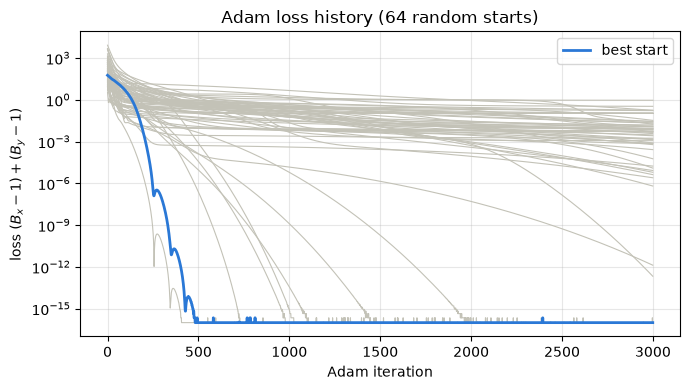

In [9]:
LOSS_FLOOR = 1.0e-16  # the loss reaches round-off level (and can become slightly negative); clip for the log plot

i_best_start = int(np.argmin(np.asarray(loss_adam)))
history_clipped = np.maximum(np.asarray(loss_history), LOSS_FLOOR)
fig, ax = plt.subplots(figsize=(7, 4))
for h in history_clipped:
    ax.semilogy(h, color=COLOR_MUTED, linewidth=0.8)
ax.semilogy(history_clipped[i_best_start], color=COLOR_X, linewidth=2.0, label="best start")
ax.set_xlabel("Adam iteration")
ax.set_ylabel(r"loss $(B_x - 1) + (B_y - 1)$")
ax.set_title(f"Adam loss history ({N_STARTS} random starts)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Beta functions along the beamline: before and after matching

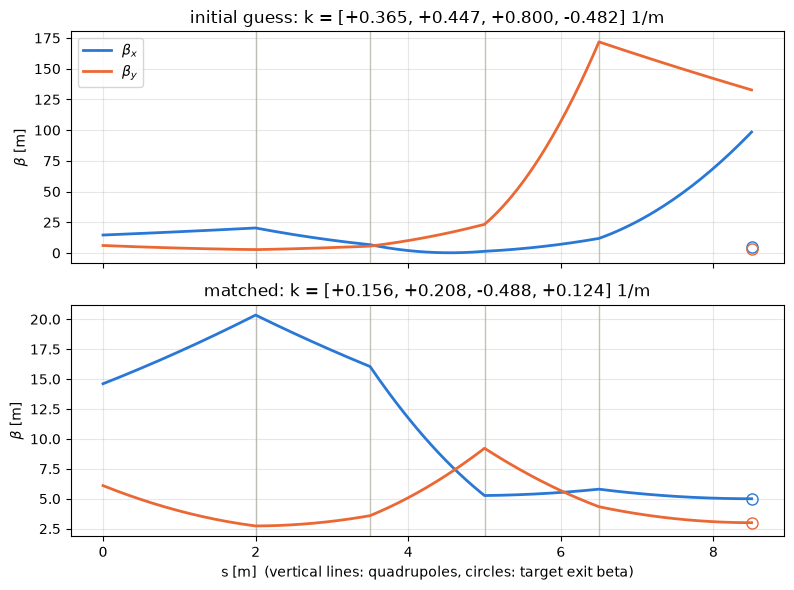

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for ax, k, title in zip(axes, (k_inits[i_best_start], k_best), ("initial guess", "matched")):
    s, beta = beta_along_line(k)
    ax.plot(s, beta[:, 0], color=COLOR_X, linewidth=2.0, label=r"$\beta_x$")
    ax.plot(s, beta[:, 1], color=COLOR_Y, linewidth=2.0, label=r"$\beta_y$")
    for i, p in enumerate(PLANES):
        ax.plot(s[-1], TWISS_TARGET[i, 0], "o", markersize=8, color=(COLOR_X, COLOR_Y)[i], mfc="none")
    for q in quad_positions:
        ax.axvline(q, color=COLOR_MUTED, linewidth=1.0, zorder=0)
    ax.set_ylabel(r"$\beta$ [m]")
    ax.set_title(f"{title}: k = [" + ", ".join(f"{v:+.3f}" for v in np.asarray(k)) + "] 1/m")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper left")
axes[-1].set_xlabel("s [m]  (vertical lines: quadrupoles, circles: target exit beta)")
fig.tight_layout()
plt.show()

### All distinct solutions

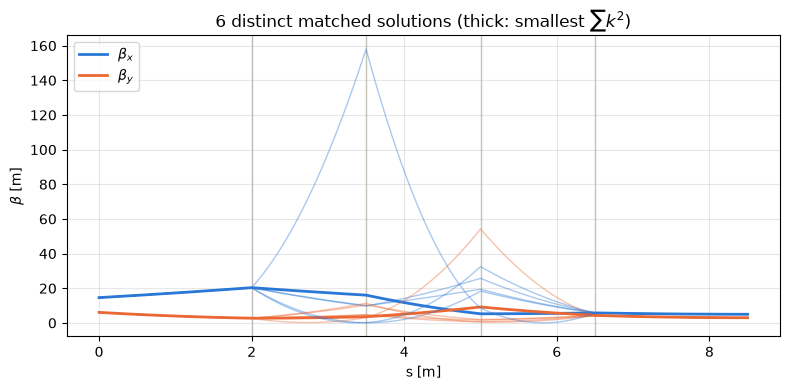

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, sol in enumerate(solutions):
    s, beta = beta_along_line(jnp.asarray(sol))
    lw = 2.0 if i == 0 else 1.0
    alpha_line = 1.0 if i == 0 else 0.4
    ax.plot(s, beta[:, 0], color=COLOR_X, linewidth=lw, alpha=alpha_line, label=r"$\beta_x$" if i == 0 else None)
    ax.plot(s, beta[:, 1], color=COLOR_Y, linewidth=lw, alpha=alpha_line, label=r"$\beta_y$" if i == 0 else None)
for q in quad_positions:
    ax.axvline(q, color=COLOR_MUTED, linewidth=1.0, zorder=0)
ax.set_xlabel("s [m]")
ax.set_ylabel(r"$\beta$ [m]")
ax.set_title(f"{len(solutions)} distinct matched solutions (thick: smallest $\\sum k^2$)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Sensitivity of the loss to entrance Twiss errors

In practice the entrance Twiss parameters are only known within measurement errors. We keep the matched
quadrupole strengths $k^\ast$ fixed and ask how much the loss grows when the *actual* entrance Twiss
parameters deviate from the assumed ones.

The entrance errors are parameterized per plane as a relative beta error and an absolute alpha error,

$$
\delta = \left( \frac{\Delta\beta_x}{\beta_x},\ \Delta\alpha_x,\ \frac{\Delta\beta_y}{\beta_y},\ \Delta\alpha_y \right),
\qquad \beta \to \beta (1 + \delta_\beta), \quad \alpha \to \alpha + \delta_\alpha .
$$

Since the loss is non-negative and vanishes at $\delta = 0$, its gradient with respect to $\delta$ is zero at the
matched point. The leading term is therefore quadratic,

$$
\mathcal{L}(\delta) \simeq \tfrac{1}{2}\, \delta^\mathsf{T} H \delta, \qquad H = \frac{\partial^2 \mathcal{L}}{\partial \delta^2}\bigg|_{\delta = 0},
$$

and the Hessian $H$ is obtained exactly with `jax.hessian`. For Gaussian errors with covariance
$\Sigma_\delta$, the expected loss is $\langle \mathcal{L} \rangle \simeq \tfrac{1}{2} \operatorname{tr}(H \Sigma_\delta)$.

In [12]:
def perturb_twiss_in(delta):
    """Entrance Twiss parameters with errors delta = [dbeta_x/beta_x, dalpha_x, dbeta_y/beta_y, dalpha_y]."""
    d = delta.reshape(2, 2)
    beta = TWISS_IN[:, 0] * (1.0 + d[:, 0])
    alpha = TWISS_IN[:, 1] + d[:, 1]
    return jnp.stack([beta, alpha], axis=1)


def loss_with_entrance_error(delta, k):
    twiss_out = propagate_twiss(k, perturb_twiss_in(delta))
    return jnp.sum(jax.vmap(bmag)(twiss_out, TWISS_TARGET) - 1.0)


delta_zero = jnp.zeros(2 * len(PLANES))
grad_delta = jax.grad(loss_with_entrance_error)(delta_zero, k_best)
hess_delta = jax.hessian(loss_with_entrance_error)(delta_zero, k_best)

DELTA_LABELS = ("dbeta_x/beta_x", "dalpha_x", "dbeta_y/beta_y", "dalpha_y")
print("gradient at delta = 0 (should vanish):", np.asarray(grad_delta))
print("Hessian H:")
print("".join(f"{lab:>16s}" for lab in ("",) + DELTA_LABELS))
for lab, row in zip(DELTA_LABELS, np.asarray(hess_delta)):
    print(f"{lab:>16s}" + "".join(f"{v:16.5f}" for v in row))

gradient at delta = 0 (should vanish): [-3.49526736e-17  4.79574983e-17  2.34637746e-15 -1.39862221e-15]
Hessian H:
                  dbeta_x/beta_x        dalpha_x  dbeta_y/beta_y        dalpha_y
  dbeta_x/beta_x         2.58288         1.25813         0.00000         0.00000
        dalpha_x         1.25813         1.00000         0.00000         0.00000
  dbeta_y/beta_y         0.00000         0.00000         2.61759        -1.27185
        dalpha_y         0.00000         0.00000        -1.27185         1.00000


### The loss sensitivity does not depend on the quadrupole setting

The mismatch parameter $B$ is invariant under any linear symplectic transport: transporting both the actual and
the design ellipse through the same beamline does not change their mismatch. Once the line is matched, the exit
mismatch therefore equals the entrance mismatch, and $H$ is the same for every solution. To second order,

$$
B - 1 \simeq \tfrac{1}{2} \left[ \left( \frac{\Delta\beta}{\beta} \right)^2
+ \left( \Delta\alpha - \alpha \frac{\Delta\beta}{\beta} \right)^2 \right],
\qquad
H_\text{plane} = \begin{pmatrix} 1 + \alpha^2 & -\alpha \\ -\alpha & 1 \end{pmatrix},
$$

where $\alpha$ is the entrance alpha of that plane. The cell below checks this against the automatic Hessian for
all distinct solutions.

In [13]:
hess_analytic = jax.scipy.linalg.block_diag(
    *[jnp.array([[1.0 + a**2, -a], [-a, 1.0]]) for a in TWISS_IN[:, 1]]
)
hess_all = jax.vmap(jax.hessian(loss_with_entrance_error), in_axes=(None, 0))(delta_zero, jnp.asarray(solutions))
for i, h in enumerate(hess_all):
    print(f"solution {i}: max |H - H_analytic| = {float(jnp.max(jnp.abs(h - hess_analytic))):.2e}")

solution 0: max |H - H_analytic| = 2.66e-15
solution 1: max |H - H_analytic| = 4.00e-15
solution 2: max |H - H_analytic| = 3.55e-15
solution 3: max |H - H_analytic| = 1.33e-15
solution 4: max |H - H_analytic| = 3.11e-15
solution 5: max |H - H_analytic| = 7.55e-15


### What does depend on the solution: the exit Twiss error

Although the overall mismatch is the same, the way an entrance error shows up at the exit, i.e. the
Jacobian $\partial (\Delta\beta/\beta, \Delta\alpha)_\text{exit} / \partial \delta$, does depend on the solution.
We summarize it with the rms exit beta-beat $\sqrt{\langle (\Delta\beta/\beta)^2 \rangle}$ for Gaussian entrance errors
of the size below, propagated linearly with the Jacobian from `jax.jacfwd`.

In [14]:
SIGMA_DBETA = 0.1  # rms relative beta error at the entrance
SIGMA_DALPHA = 0.1  # rms alpha error at the entrance
COV_DELTA = jnp.diag(jnp.array([SIGMA_DBETA, SIGMA_DALPHA] * len(PLANES)) ** 2)


def exit_error(delta, k):
    """Exit [dbeta_x/beta_x, dalpha_x, dbeta_y/beta_y, dalpha_y] caused by entrance errors delta."""
    twiss_out = propagate_twiss(k, perturb_twiss_in(delta))
    d_beta = (twiss_out[:, 0] - TWISS_TARGET[:, 0]) / TWISS_TARGET[:, 0]
    d_alpha = twiss_out[:, 1] - TWISS_TARGET[:, 1]
    return jnp.stack([d_beta, d_alpha], axis=1).ravel()


jac_exit_all = jax.vmap(jax.jacfwd(exit_error), in_axes=(None, 0))(delta_zero, jnp.asarray(solutions))
expected_loss = 0.5 * jnp.trace(hess_analytic @ COV_DELTA)
print(f"expected loss 0.5 tr(H Sigma) = {float(expected_loss):.4e}  (same for all solutions)")
print("solution   sum k^2   rms dbeta/beta exit x   rms dbeta/beta exit y")
for i, (sol, jac) in enumerate(zip(solutions, jac_exit_all)):
    cov_exit = jac @ COV_DELTA @ jac.T
    rms_x, rms_y = np.sqrt(np.asarray(cov_exit)[[0, 2], [0, 2]])
    print(f"{i:8d} {np.sum(sol**2):9.4f} {rms_x:23.4f} {rms_y:23.4f}")

expected loss 0.5 tr(H Sigma) = 3.6002e-02  (same for all solutions)
solution   sum k^2   rms dbeta/beta exit x   rms dbeta/beta exit y
       0    0.3210                  0.1809                  0.1821
       1    0.8363                  0.1698                  0.0895
       2    1.3899                  0.1660                  0.1540
       3    2.1960                  0.0746                  0.1730
       4    3.1620                  0.0767                  0.1821
       5    5.4319                  0.0645                  0.1649


### Monte Carlo check of the quadratic approximation

Finally we sample random entrance errors, evaluate the full nonlinear loss with `jax.vmap`, and compare it with
the quadratic prediction $\tfrac{1}{2}\delta^\mathsf{T} H \delta$. Scanning the error size shows where the
quadratic approximation stops being accurate.

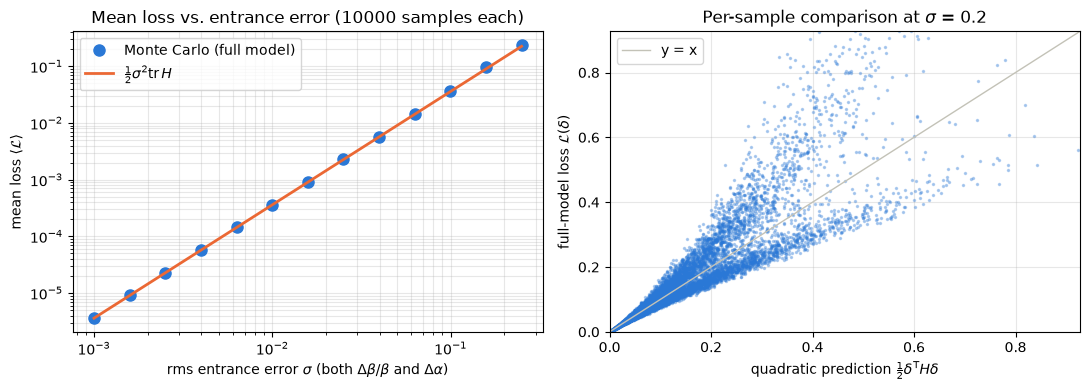

In [15]:
N_MC = 10000
MC_SEED = 2
# Common rms of dbeta/beta and dalpha. Keep it well below 1 so that beta*(1 + dbeta/beta) stays positive.
ERROR_SCALES = jnp.geomspace(1.0e-3, 0.25, 13)
SCATTER_SCALE = 0.2  # error size used for the scatter plot

unit_samples = jax.random.normal(jax.random.PRNGKey(MC_SEED), (N_MC, 2 * len(PLANES)))
loss_mc_fn = jax.jit(jax.vmap(loss_with_entrance_error, in_axes=(0, None)))


def quadratic_loss(delta):
    return 0.5 * jnp.einsum("ni,ij,nj->n", delta, hess_delta, delta)


mean_loss_mc = jnp.array([jnp.mean(loss_mc_fn(s * unit_samples, k_best)) for s in ERROR_SCALES])
mean_loss_quad = 0.5 * jnp.trace(hess_delta) * ERROR_SCALES**2

delta_scatter = SCATTER_SCALE * unit_samples
loss_scatter_mc = loss_mc_fn(delta_scatter, k_best)
loss_scatter_quad = quadratic_loss(delta_scatter)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.loglog(ERROR_SCALES, mean_loss_mc, "o", markersize=8, color=COLOR_X, label="Monte Carlo (full model)")
ax.loglog(ERROR_SCALES, mean_loss_quad, color=COLOR_Y, linewidth=2.0, label=r"$\frac{1}{2}\sigma^2 \mathrm{tr}\,H$")
ax.set_xlabel(r"rms entrance error $\sigma$ (both $\Delta\beta/\beta$ and $\Delta\alpha$)")
ax.set_ylabel(r"mean loss $\langle \mathcal{L} \rangle$")
ax.set_title(f"Mean loss vs. entrance error ({N_MC} samples each)")
ax.legend()
ax.grid(alpha=0.3, which="both")

ax = axes[1]
lim = float(jnp.quantile(loss_scatter_mc, 0.99))
ax.plot(loss_scatter_quad, loss_scatter_mc, ".", markersize=3, color=COLOR_X, alpha=0.3)
ax.plot([0.0, lim], [0.0, lim], color=COLOR_MUTED, linewidth=1.0, label="y = x")
ax.set_xlim(0.0, lim)
ax.set_ylim(0.0, lim)
ax.set_xlabel(r"quadratic prediction $\frac{1}{2}\delta^\mathsf{T} H \delta$")
ax.set_ylabel(r"full-model loss $\mathcal{L}(\delta)$")
ax.set_title(f"Per-sample comparison at $\\sigma$ = {SCATTER_SCALE}")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Observations**

- The gradient of the loss with respect to the entrance errors vanishes at the matched point, so a first-order
  sensitivity analysis says nothing; the Hessian is the relevant quantity.
- The Hessian is identical for all matched solutions and agrees with the analytic formula, reflecting the
  invariance of the mismatch parameter under linear transport. Choosing a different quadrupole solution cannot
  make the matching more robust in terms of $B$; it only redistributes the error between $\Delta\beta/\beta$ and
  $\Delta\alpha$ at the exit.
- The mean loss follows $\tfrac{1}{2}\sigma^2 \operatorname{tr} H$ up to $\sigma \sim 0.1$. At larger errors the
  per-sample scatter shows clear deviations from the quadratic model, i.e. the higher-order terms of $B$ in
  $\Delta\beta/\beta$ become significant.